## Chapter 4: Testing and regularization

In [2]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
random.seed(0)

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

### Defining our dataset

Plotting the polynomial $-x^2+2$

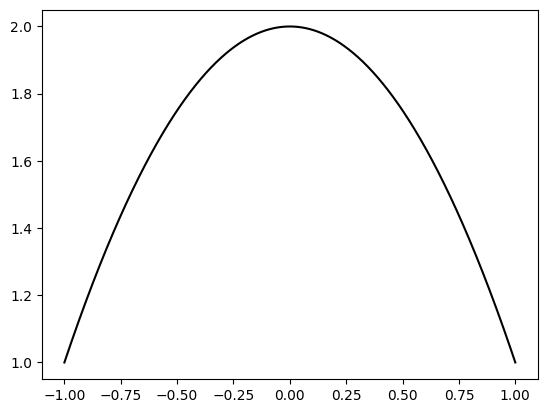

In [3]:
coefs = [2, 0, -1]

def polynomial(coefs, x):
    n = len(coefs)
    return sum([coefs[i] * (x ** i) for i in range(n)]) # 2 + 0x + (-1)x^2

def draw_polynomial(coefs):
    n = len(coefs)
    x = np.linspace(-1, 1, 1000)
    #plt.ylim(0, 3)

    plt.plot(x, sum([coefs[i] * (x ** i) for i in range(n)]), linestyle="-", color="black")

draw_polynomial(coefs)

Generating a dataset of 40 points, close to this polynomial

In [4]:
X = []
Y = []

for i in range(40):
    x = random.uniform(-1, 1)
    y = polynomial(coefs, x) + random.gauss(0, 0.1) 
    X.append(x)
    Y.append(y)

**random.gauss(0, 0.1)** generates noise from a Gaussian (normal) distribution with mean 0 and standard deviation 0.1. The noise is usually small, but can be positive or negative.

After the loop, both lists contain 40 values. Together, they represent sample points from the polynomial with added noise.

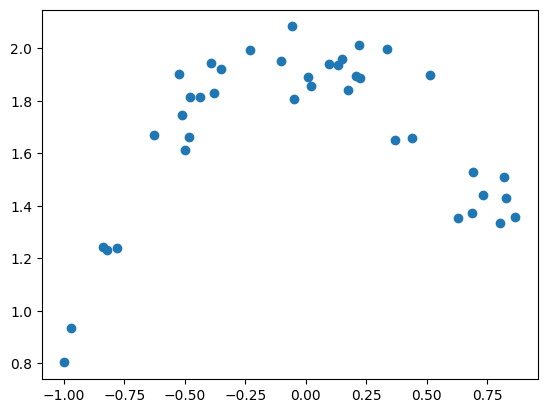

In [5]:
plt.scatter(X, Y)

### Training a polynomial regression model

Let's plot a polynomial of degree 20 to our dataset. Notice how much it overfits!

In [7]:
def train_polynomial_regression(X, Y, degree, regularization=None, alpha=1.0):
  """
  Trains a polynomial regression model with optional L1 or L2 regularization.

  Args:
    X: Input features (list or numpy array).
    Y: Input labels (list or numpy array).
    degree: The degree of the polynomial.
    regularization: Type of regularization ('L1', 'L2', or None). Defaults to None.
    alpha: Regularization strength (for L1 and L2). Defaults to 1.0.

  Returns:
    A trained scikit-learn model object (LinearRegression, Ridge, or Lasso).
  """

  X = np.array(X).reshape(-1, 1)
  Y = np.array(Y)

  poly = PolynomialFeatures(degree=degree, include_bias=False)
  X_poly = poly.fit_transform(X)

  if regularization == "L1":
    model = Lasso(alpha=alpha)
  elif regularization == "L2":
    model = Ridge(alpha=alpha)
  else:
    model = LinearRegression()

  model.fit(X_poly, Y)

  return model

In [8]:
degree_used = 20
model = train_polynomial_regression(X, Y, degree_used)